## Workshop-1-Adding-Sunglasses-to-Your-Passport-Photo-Using-OpenCV
## Name : Navasri B
## Reg No: 212225230196

In [4]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

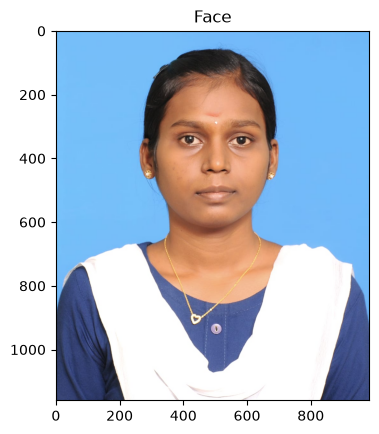

In [5]:
# Load the Face Image
faceImage = cv2.imread('Nava_sri.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [6]:
faceImage.shape

(1160, 984, 3)

In [7]:
#resized_faceImage.shape
faceImage.shape

(1160, 984, 3)

Text(0.5, 1.0, 'glassPNG')

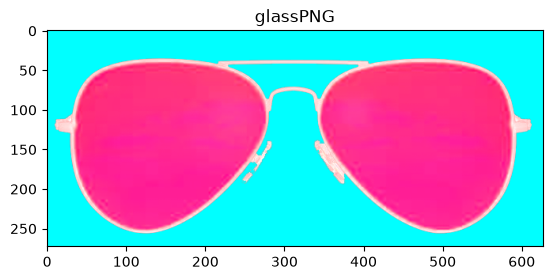

In [8]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [9]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(250, 80))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(80, 250, 4)


In [10]:
# Separate color and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]

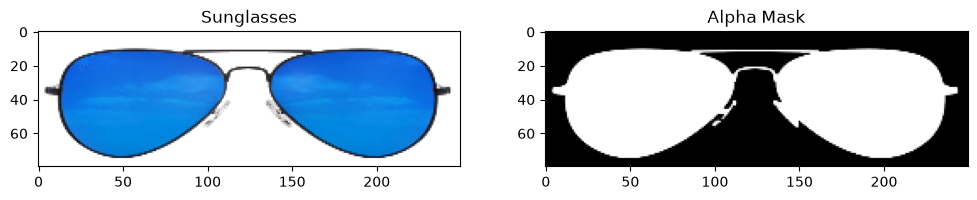

In [11]:
# Display sunglasses and alpha mask
plt.figure(figsize=(12,5))

plt.subplot(121)
plt.imshow(glassBGR[:,:,::-1])
plt.title("Sunglasses")

plt.subplot(122)
plt.imshow(glassMask1, cmap="gray")
plt.title("Alpha Mask")

plt.show()

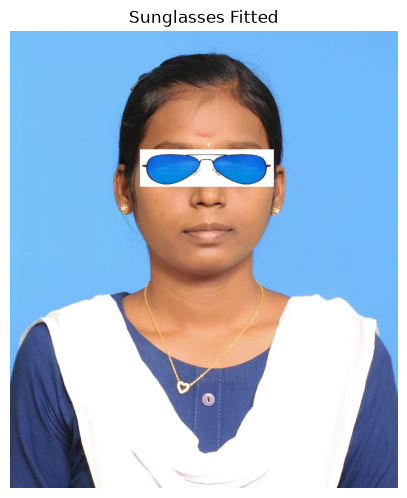

In [26]:

# Make a copy of the original face image
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses with background
glassResized = cv2.resize(glassBGR, (340, 95))

# Set glasses position
x = 330  # Slightly left
y = 300  # Slightly upward

# Get sunglasses dimensions
h, w = glassResized.shape[:2]

# Select face region
roi = faceWithGlassesNaive[y:y+h, x:x+w]

# Place sunglasses with original background
faceWithGlassesNaive[y:y+h, x:x+w] = glassResized

# Display medium-size photo
plt.figure(figsize=(5, 7))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses Fitted")
plt.axis("off")
plt.show()


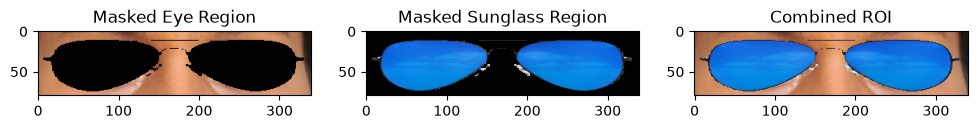

In [27]:

# Resize mask to match wider sunglasses
glassBGR = cv2.resize(glassBGR, (340, 80))
glassMask1 = cv2.resize(glassMask1, (340, 80),
                        interpolation=cv2.INTER_NEAREST)

# Create 3-channel mask
glassMask = cv2.merge((glassMask1,
                       glassMask1,
                       glassMask1))

# Convert mask values to 0 and 1
glassMask = np.uint8(glassMask / 255)

# Make a copy of face image
faceWithGlasses = faceImage.copy()

# EYE REGION COORDINATES
x = 330   # Slightly left to keep glasses centered
y = 300   # Same upward position

h = glassBGR.shape[0]
w = glassBGR.shape[1]

# Extract eye ROI
eyeROI = faceWithGlasses[y:y+h, x:x+w]

# Remove region where glasses will be placed
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Extract glasses using mask
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace eye region with combined image
faceWithGlasses[y:y+h, x:x+w] = eyeRoiFinal

# Intermediate Results
plt.figure(figsize=(12, 5))

plt.subplot(131)
plt.imshow(maskedEye[:,:,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[:,:,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeRoiFinal[:,:,::-1])
plt.title("Combined ROI")

plt.show()


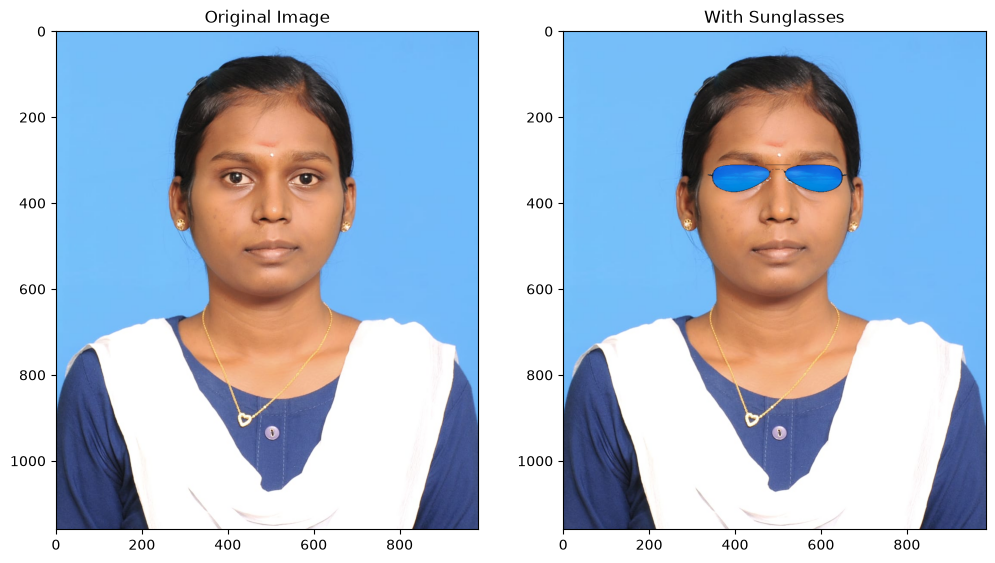

In [28]:
# Final Result
plt.figure(figsize=(12,8))

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")
plt.axis("on")

plt.subplot(122)
plt.imshow(faceWithGlasses[:,:,::-1])
plt.title("With Sunglasses")
plt.axis("on")

plt.show()